# 07 Results comparison and error analysis

This notebook rebuilds every number in the report from the saved experiment logs (`results/experiment_logs/`)
and test-set probabilities (`results/predictions/`). Nothing is retrained here.

If you ran notebook 06 on Colab and copied its `results/` folder back, the fine-tuned Transformer is included automatically.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Change this to your own GitHub repository before running in Colab
REPO_URL = "https://github.com/YOUR-GITHUB-USERNAME/lingala-news-classification.git"

if IN_COLAB and not Path("lingala-news-classification").exists():
    !git clone -q {REPO_URL}
if IN_COLAB:
    %cd lingala-news-classification
    %pip install -q -r requirements.txt

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /home/claude/lingala-news-classification


In [2]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_loading, evaluation, plots
from src.experiment_log import load_all_experiments
from src.text_processing import tokenise

COMPARISON_DIRECTORY = config.RESULTS_DIRECTORY / "comparison"
COMPARISON_DIRECTORY.mkdir(parents=True, exist_ok=True)

train, validation, test = data_loading.load_all_splits()
test_ids = data_loading.labels_to_ids(test["category"])
logs = load_all_experiments()
predictions = evaluation.load_test_predictions()
print("Models with saved test predictions:", list(predictions))

Models with saved test predictions: ['majority', 'rnn', 'tfidf_best', 'tfidf_naive_bayes', 'transformer_scratch', 'word2vec_average']


## 1. All validation experiments

In [3]:
pd.set_option("display.max_colwidth", 60)
validation_table = logs[logs["split"].isin(["validation", "cv_train"])].pivot_table(
    index=["model_family", "experiment"], columns="split", values="macro_f1", aggfunc="last")
cv_std = logs[logs["split"] == "cv_train"].set_index(["model_family", "experiment"])["macro_f1_std"]
validation_table["cv_train_std"] = cv_std
notes = logs[logs["split"] == "validation"].drop_duplicates(["model_family", "experiment"], keep="last").set_index(["model_family", "experiment"])["notes"]
validation_table["what changed"] = notes
validation_table = validation_table.rename(columns={"validation": "validation macro-F1", "cv_train": "CV macro-F1 (train)", "cv_train_std": "CV std"})
validation_table.round(3).to_csv(COMPARISON_DIRECTORY / "all_validation_experiments.csv")
validation_table.round(3)

split                                             CV macro-F1 (train)  \
model_family        experiment                                          
bag_of_words        A1_majority                                 0.183   
                    A2_nb_alpha1                                0.216   
                    A3_nb_alpha0.1                              0.684   
                    A4_complement_nb                            0.746   
                    A5_logreg                                   0.760   
                    A6_logreg_balanced                          0.840   
                    A7_svm_balanced                             0.854   
                    B1_word_1-2grams                            0.789   
                    B2_char_2-5                                 0.852   
                    B3_char_3-6                                 0.848   
                    B4_word+char                                0.845   
                    B5_svm_word+char                            0.855   
                    C1_headline_only                            0.710   
                    C2_text_only                                0.851   
                    C3_strip_accents                            0.858   
                    D_C=0.1                                     0.843   
                    D_C=10                                      0.861   
rnn                 R1_bilstm_random_embeddings                   NaN   
                    R2_bilstm_word2vec_finetuned                  NaN   
                    R3_bilstm_word2vec_frozen                     NaN   
                    R4_bilstm_last_state                          NaN   
                    R5_bigru_attention                            NaN   
                    R6_bilstm_no_class_weights                    NaN   
transformer_scratch T1_2layers_128d                               NaN   
                    T2_4layers_256d                               NaN   
                    T3_2layers_512tokens                          NaN   
word2vec            W1_skipgram_100d                              NaN   
                    W2_cbow_100d                                  NaN   
                    W3_skipgram_300d                              NaN   
                    W4_skipgram_window10                          NaN   
                    W5_skipgram_strip_accents                     NaN   

split                                             validation macro-F1  CV std  \
model_family        experiment                                                  
bag_of_words        A1_majority                                 0.182   0.000   
                    A2_nb_alpha1                                0.233   0.020   
                    A3_nb_alpha0.1                              0.753   0.029   
                    A4_complement_nb                            0.828   0.048   
                    A5_logreg                                   0.787   0.035   
                    A6_logreg_balanced                          0.902   0.049   
                    A7_svm_balanced                             0.902   0.046   
                    B1_word_1-2grams                            0.866   0.048   
                    B2_char_2-5                                 0.868   0.024   
                    B3_char_3-6                                 0.868   0.028   
                    B4_word+char                                0.881   0.032   
                    B5_svm_word+char                            0.881   0.022   
                    C1_headline_only                            0.762   0.039   
                    C2_text_only                                0.881   0.020   
                    C3_strip_accents                            0.881   0.022   
                    D_C=0.1                                     0.902   0.029   
                    D_C=10                                      0.881   0.028   
rnn                 R1_bilstm_random_embeddings    

## 2. Final test-set results
Neural models: mean ± standard deviation over 3 seeds. Bag-of-words models are deterministic, so they have one score
(their variability is shown by the cross-validation std above). The 95% interval is a bootstrap over the 175 test articles.

In [4]:
DISPLAY_NAMES = {
    "majority": "Majority class",
    "tfidf_naive_bayes": "TF-IDF + Naive Bayes",
    "tfidf_best": "TF-IDF (word+char) + linear SVM",
    "word2vec_average": "Averaged Word2Vec + LogReg",
    "rnn": "BiLSTM + attention (Word2Vec init)",
    "transformer_scratch": "Transformer from scratch",
    "transformer": "Fine-tuned pretrained Transformer",
}
FAMILY_OF = {"majority": "bag_of_words", "tfidf_naive_bayes": "bag_of_words", "tfidf_best": "bag_of_words",
             "word2vec_average": "word2vec", "rnn": "rnn", "transformer_scratch": "transformer_scratch",
             "transformer": "transformer_pretrained"}

final_logs = logs[(logs["split"] == "test") & logs["experiment"].str.startswith("FINAL")]
rows = []
for name in DISPLAY_NAMES:
    if name not in predictions:
        continue
    family_rows = final_logs[final_logs["model_family"] == FAMILY_OF[name]]
    if FAMILY_OF[name] == "bag_of_words":
        family_rows = family_rows[family_rows["experiment"] == f"FINAL_{name}"]
    row = family_rows.iloc[-1]
    std = row.get("macro_f1_std")
    rows.append({
        "model": DISPLAY_NAMES[name],
        "macro-F1": row["macro_f1"],
        "± std (seeds)": None if pd.isna(std) else std,
        "95% CI": f"{row['macro_f1_ci_low']:.3f}-{row['macro_f1_ci_high']:.3f}",
        "weighted-F1": row["weighted_f1"],
        "accuracy": row["accuracy"],
        "macro precision": row["macro_precision"],
        "macro recall": row["macro_recall"],
        **{f"F1 {label}": row[f"f1_{label}"] for label in config.LABELS},
        "key": name,
    })
final_table = pd.DataFrame(rows)
final_table.drop(columns="key").round(3).to_csv(COMPARISON_DIRECTORY / "final_test_results.csv", index=False)
final_table.drop(columns="key").round(3)

,model,macro-F1,± std (seeds),95% CI,weighted-F1,accuracy,macro precision,macro recall,F1 politics,F1 health,F1 sports,F1 business
0,Majority class,0.182,NaN,0.165-0.196,0.416,0.571,0.143,0.250,0.727,0.000,0.000,0.000
1,TF-IDF + Naive Bayes,0.673,NaN,0.609-0.738,0.773,0.811,0.929,0.653,0.857,0.750,0.973,0.111
2,TF-IDF (word+char) + linear SVM,0.822,NaN,0.747-0.884,0.852,0.857,0.877,0.786,0.884,0.812,0.973,0.621
3,Averaged Word2Vec + LogReg,0.860,NaN,0.797-0.909,0.875,0.874,0.870,0.865,0.898,0.824,1.000,0.718
4,BiLSTM + attention (Word2Vec init),0.861,0.018,0.769-0.903,0.882,0.886,0.900,0.838,0.903,0.859,1.000,0.683
5,Transformer from scratch,0.752,0.041,0.702-0.836,0.822,0.821,0.773,0.740,0.879,0.809,0.945,0.374


### Context: published MasakhaNEWS results for Lingala
Adelani et al. (2023, Table 3) report **weighted-F1** on the same test set (headline + text): MLP 84.3, Naive Bayes 82.8,
XGBoost 74.8, AfriBERTa 87.0, XLM-R-base 87.9, AfroXLMR-base 93.0, XLM-R-large 91.8, AfroXLMR-large 93.7.
Compare these with our weighted-F1 column, not with macro-F1.

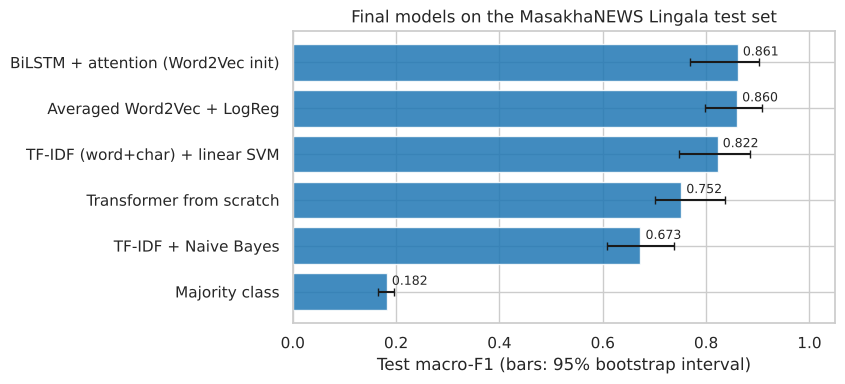

In [5]:
figure, axis = plt.subplots(figsize=(7, 3.8))
ordered = final_table.sort_values("macro-F1")
low = ordered["macro-F1"] - ordered["95% CI"].str.split("-").str[0].astype(float)
high = ordered["95% CI"].str.split("-").str[1].astype(float) - ordered["macro-F1"]
axis.barh(ordered["model"], ordered["macro-F1"], xerr=[low, high], color="tab:blue", alpha=0.85, capsize=3)
for y, value in enumerate(ordered["macro-F1"]):
    axis.text(value + 0.01, y + 0.15, f"{value:.3f}", fontsize=9)
axis.set_xlim(0, 1.05)
axis.set_xlabel("Test macro-F1 (bars: 95% bootstrap interval)")
axis.set_title("Final models on the MasakhaNEWS Lingala test set")
figure.savefig(COMPARISON_DIRECTORY / "test_macro_f1.png", dpi=150, bbox_inches="tight")

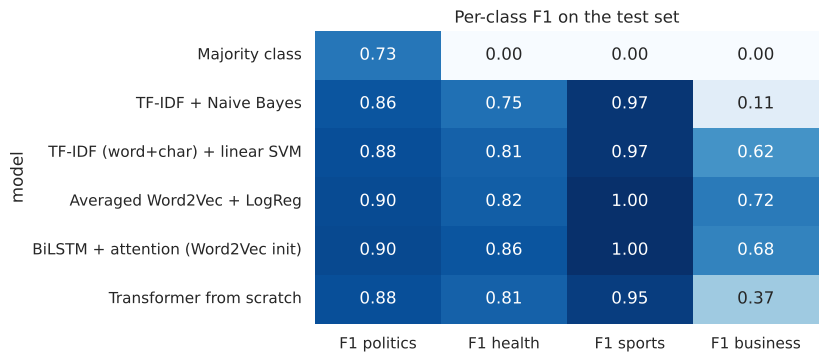

In [6]:
per_class = final_table.set_index("model")[[f"F1 {label}" for label in config.LABELS]]
figure, axis = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axis, cbar=False)
axis.set_title("Per-class F1 on the test set")
figure.savefig(COMPARISON_DIRECTORY / "per_class_f1.png", dpi=150, bbox_inches="tight")

## 3. Are the differences real? Paired bootstrap test
For each model we resample the test articles 2,000 times and count how often it does **not** beat the TF-IDF + SVM baseline
on macro-F1. A value below 0.05 means the improvement (or, if the model is worse, the gap is reversed) is unlikely to be luck.

In [7]:
baseline = predictions["tfidf_best"].argmax(1)
rows = []
for name, probabilities in predictions.items():
    if name == "tfidf_best":
        continue
    model_predictions = probabilities.argmax(1)
    rows.append({
        "model": DISPLAY_NAMES.get(name, name),
        "share of resamples where it is NOT better than TF-IDF+SVM": evaluation.paired_bootstrap_test(test_ids, baseline, model_predictions),
        "articles it gets right that TF-IDF+SVM gets wrong": int(((model_predictions == test_ids) & (baseline != test_ids)).sum()),
        "articles TF-IDF+SVM gets right that it gets wrong": int(((model_predictions != test_ids) & (baseline == test_ids)).sum()),
    })
significance = pd.DataFrame(rows)
significance.to_csv(COMPARISON_DIRECTORY / "paired_bootstrap_vs_tfidf.csv", index=False)
significance

,model,share of resamples where it is NOT better than TF-IDF+SVM,articles it gets right that TF-IDF+SVM gets wrong,articles TF-IDF+SVM gets right that it gets wrong
0,Majority class,1.000,5,55
1,BiLSTM + attention (Word2Vec init),0.250,8,5
2,TF-IDF + Naive Bayes,1.000,4,12
3,Transformer from scratch,0.871,12,15
4,Averaged Word2Vec + LogReg,0.103,8,5


## 4. Error analysis of the deployed model
We analyse the fine-tuned Transformer if its predictions are available, otherwise the TF-IDF + SVM model.

Analysing: TF-IDF (word+char) + linear SVM
25 errors out of 175 test articles


errors
true_label predicted_label        
health     politics             11
business   politics              8
politics   business              3
           health                2
sports     politics              1

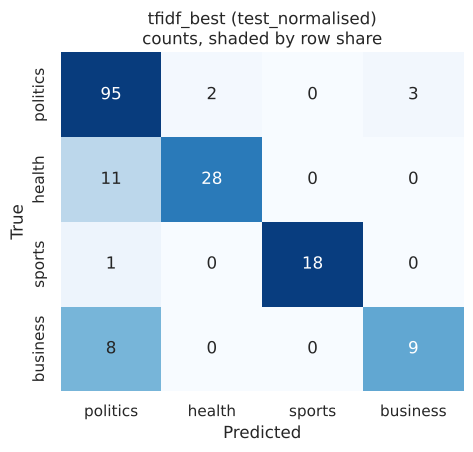

In [8]:
ANALYSED = "transformer" if "transformer" in predictions else "tfidf_best"
probabilities = predictions[ANALYSED]
print("Analysing:", DISPLAY_NAMES[ANALYSED])
table = evaluation.build_prediction_table(test, test_ids, probabilities)
plots.plot_confusion_matrix(test_ids, probabilities, ANALYSED, "test_normalised", normalise=True)
print(f"{(~table['correct']).sum()} errors out of {len(table)} test articles")
errors = table[~table["correct"]]
errors.groupby(["true_label", "predicted_label"]).size().sort_values(ascending=False).to_frame("errors")

### 4.1 Do errors depend on length, unseen words, French or confidence?

In [9]:
train_vocabulary = {w for text in train["content"] for w in tokenise(text)}
french_pattern = re.compile(r"[éèêëàâçôûùîï]|(?:tion|ment|ique|eur|aire)s?$")

def unseen_share(text):
    tokens = tokenise(text)
    return np.mean([t not in train_vocabulary for t in tokens])

def french_share(text):
    tokens = tokenise(text)
    return np.mean([bool(french_pattern.search(t)) for t in tokens])

table["unseen_word_share"] = table["content"].apply(unseen_share)
table["french_like_share"] = table["content"].apply(french_share)
factors = table.groupby("correct")[["words", "unseen_word_share", "french_like_share", "confidence"]].mean().round(3)
factors.index = factors.index.map({True: "correct", False: "wrong"})
display(factors)

bins = pd.cut(table["confidence"], [0, 0.5, 0.7, 0.9, 1.0])
reliability = table.groupby(bins, observed=True)["correct"].agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "articles"})
reliability.round(3)

,words,unseen_word_share,french_like_share,confidence
correct,,,,
wrong,176.760,0.065,0.057,0.657
correct,182.633,0.067,0.041,0.896


,accuracy,articles
confidence,,
"(0.0, 0.5]",0.400,5
"(0.5, 0.7]",0.450,20
"(0.7, 0.9]",0.800,45
"(0.9, 1.0]",0.981,105


**Reading this table.** If wrong predictions have clearly lower confidence, the model "knows when it does not know", which the
web app uses to warn the user. If wrong articles are not longer and do not have more unseen words, the errors are not caused by
truncation or vocabulary gaps but by the **content**: articles that genuinely mix topics.

### 4.2 Articles that every model gets wrong

In [10]:
real_models = [n for n in predictions if n != "majority"]
wrong_by = pd.DataFrame({DISPLAY_NAMES[n]: predictions[n].argmax(1) != test_ids for n in real_models})
table["models_wrong"] = wrong_by.sum(axis=1).to_numpy()
hard = table[table["models_wrong"] == len(real_models)].copy()
for n in real_models:
    hard[n] = [config.LABELS[i] for i in predictions[n].argmax(1)[hard.index]]
print(f"{len(hard)} test articles are misclassified by all {len(real_models)} non-trivial models")
hard[["headline", "true_label"] + real_models].to_csv(COMPARISON_DIRECTORY / "hard_examples.csv", index=False)
hard[["headline", "true_label"] + real_models]

6 test articles are misclassified by all 5 non-trivial models


,headline,true_label,rnn,tfidf_best,tfidf_naive_bayes,transformer_scratch,word2vec_average
10,Basali ya société canadienne Banro bakangami na basimba ...,business,politics,politics,politics,politics,politics
14,Ouganda na RDC batie manzaka na boyokani mpo na botongam...,business,politics,politics,politics,politics,politics
41,Parlement endimi kobakisa mikolo na état d'urgence sanit...,health,politics,politics,politics,politics,politics
46,Etat d'urgence na Congo-Brazzaville mpo na mpela,health,politics,politics,politics,business,politics
48,Assemblée nationale endimi kobakisi mikolo na état d'urg...,health,politics,politics,politics,politics,politics
50,Minganga 266 bazongi Congo-Brazzaville nsima kosilisa ke...,health,politics,politics,politics,business,politics


These are the best candidates for **label ambiguity**: when models with completely different inductive biases (word counts,
character n-grams, sequence models, pretrained Transformers) all agree on another topic, the article usually discusses two topics
(for example the provincial assembly cancelling a session because of COVID-19, labelled *health*), and the annotators' choice is
one of two defensible answers. This is consistent with the moderate annotator agreement reported for Lingala (Fleiss' kappa 0.56).

### 4.3 Most confident errors and most confident successes

In [11]:
columns = ["headline", "true_label", "predicted_label", "confidence", "words"]
print("Most confident errors:")
display(errors.sort_values("confidence", ascending=False)[columns].head(8))
print("Most confident correct prediction per class:")
display(table[table["correct"]].sort_values("confidence", ascending=False).groupby("true_label").head(2)[columns])
errors.sort_values("confidence", ascending=False).to_csv(COMPARISON_DIRECTORY / f"errors_{ANALYSED}.csv", index=False)

Most confident errors:


,headline,true_label,predicted_label,confidence,words
26,UE elaki Tshisekedi kobakisa 50 millions $ mpo na bitumb...,health,politics,0.9229,150
10,Basali ya société canadienne Banro bakangami na basimba ...,business,politics,0.9023,154
48,Assemblée nationale endimi kobakisi mikolo na état d'urg...,health,politics,0.8763,220
41,Parlement endimi kobakisa mikolo na état d'urgence sanit...,health,politics,0.8302,73
3,Sassou asengi lisungi mpo na Fonds bleu ya bassain ya Co...,business,politics,0.8213,174
14,Ouganda na RDC batie manzaka na boyokani mpo na botongam...,business,politics,0.8144,299
111,"Pompeo akebisi mpo na ""bilaka ya bampa"" ya Chine na Afrique",politics,business,0.7877,232
25,"Kamerhe atiami na ""respiration artificielle"" (Michel Moto)",health,politics,0.7740,151


Most confident correct prediction per class:


,headline,true_label,predicted_label,confidence,words
73,Député provincial Assamba atindami boloko ya Bunia na ko...,politics,politics,0.9857,258
21,B'échantillons ya Lubumbashi ezali COVID-19 te,health,health,0.9852,92
84,Washington esengi polele emonisama na maponami ya RDC,politics,politics,0.9843,107
172,Ba Léopards babetami lisusu fimbu na CAN 2019 na ba Phar...,sports,sports,0.9841,177
52,Bakoni ba COVID-19 bakomi 30 na Kinshasa,health,health,0.9836,158
162,Fifa endimi ete ba matches ya éliminatoires ya Mondial Q...,sports,sports,0.9802,139
7,"Cour ya cassation ebakisi etumbu na DG ya FONER, ya OVD ...",business,business,0.7774,119
15,FMI elobi nkita ekiti moke na RDC,business,business,0.7676,190
